## <span style="background-color:#FFE6E6"> 1. 인공신경망의 시작: 퍼셉트론 </span>


### <span style="color:violet"> 1-1 인공신경망과 퍼셉트론 </span>
> 인공신경망: 뇌의 신경망을 모방한 모델 <br>

 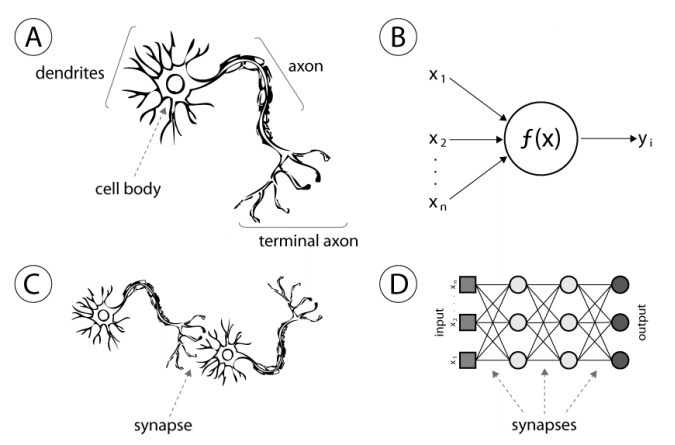
- 뉴런은 여러 신호를 받아서, 합이 일정 크기를 넘으면 다음 뉴런으로 전달함.


> 퍼셉트론: 초기 형태의 인공신경망. 딥러닝의 기원이 된 선형 이진 분류기 <br>

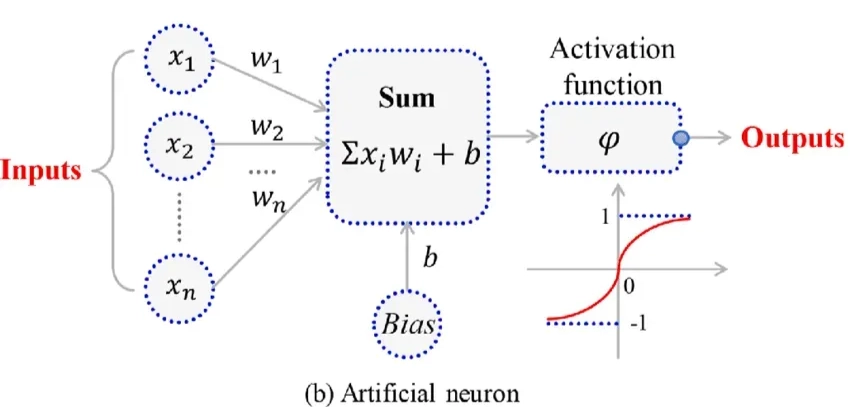
- 입력 → 가중합 → 활성화 함수 → 출력
- 입력값에 가중치를 곱해 더한 값이 임계값을 넘으면 1, 아니면 0을 출력.
- 학습: 원하는 출력이 나오도록 가중치를 조정하는 과정.


### <span style="color:violet"> 주요 용어 </span>
- **가중치(w)**: 입력값이 출력에 주는 영향력. 클수록 그 입력이 중요하다는 뜻.
- **활성화 함수**: 가중합을 받아 출력값을 결정하는 함수. 퍼셉트론은 계단 함수를 사용.

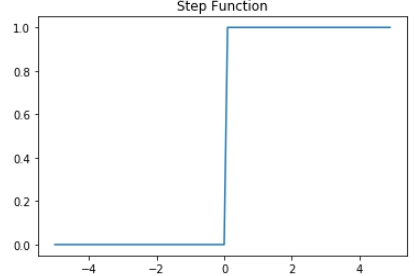

- **임계값($\theta$)**: 활성화 함수에 사용되는 갓으로 가중합>임계값 => 1, 가중합<임계값 => 0출력

\begin{aligned}&\text{if } \sum_{i}^{n} w_i x_i \ge \theta \rightarrow y=1 \\&\text{if } \sum_{i}^{n} w_i x_i < \theta \rightarrow y=0\end{aligned}

- **편향(b)**: 임계값을 좌변으로 넘긴 것($b = -\theta$). 둘은 표현의 차이일 뿐이고, 요즘은 편향을 주로 씀.

\begin{aligned}&\text{if } \sum_{i}^{n} w_i x_i + b \ge 0\rightarrow y=1 \\&\text{if } \sum_{i}^{n} w_i x_i + b < 0\rightarrow y=0\end{aligned}


### <span style="color:violet"> 1-2 단층 퍼셉트론과 한계 </span>
> 단층 퍼셉트론: 입력층과 출력층만 있는 퍼셉트론 <br>
w1, w2, b만 바꾸면 AND, OR, NAND 게이트를 만들 수 있음.

| 게이트 | 조건 | [w1, w2, b] 예시 |
| --- | --- | --- |
| AND | 둘 다 1일 때만 1 | [0.5, 0.5, -0.7] |
| OR | 하나라도 1이면 1 | [0.6, 0.6, -0.5] |
| NAND | 둘 다 1일 때만 0 | [-0.5, -0.5, 0.7] |
| XOR | 서로 다를 때만 1 | 조합 없음 |

- 퍼셉트론은 입력과 가중치의 선형 결합이라 직선 하나로 나눌 수 있는 문제만 풀 수 있음.
- XOR은 직선 하나로 나눌 수 없어서 단층 퍼셉트론으로는 구현이 불가능함.

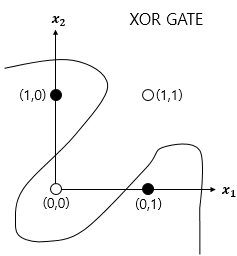


### <span style="color:violet"> 1-3 다층 퍼셉트론 (MLP) </span>
> 입력층과 출력층 사이에 은닉층을 추가한 구조 <br>
XOR = AND(NAND, OR). 즉 게이트를 조합하면 XOR을 만들 수 있음.

- 단, 층만 쌓는다고 해결되지는 않음. 활성화 함수가 없으면 여러 층이 하나의 선형식으로 합쳐짐.

$$
y = W_2(W_1x+b_1)+b_2 = (W_2W_1)x+(W_2b_1+b_2) = Wx+b
$$

- 은닉층에서 비선형 활성화 함수로 새로운 특징을 만들고, 다음 층이 그 특징을 조합하기 때문에 XOR이 풀림.

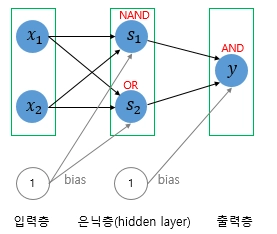

- 은닉층이 2개 이상이면 심층 신경망(DNN), 이를 학습시키는 것이 딥러닝.

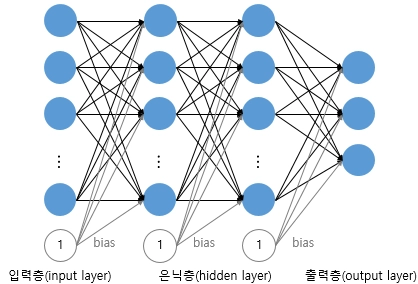


## <span style="background-color:#FFE6E6"> 2. 딥러닝의 학습방법 </span>


### <span style="color:violet"> 2-1 순전파와 역전파 </span>
> 순전파로 예측 → 손실 계산 → 역전파로 오차 전달 → 가중치 업데이트, 이 과정을 반복함. 그 결과, 오차값이 0에 가까워짐.

- 순전파(예측): 입력값이 각 층을 통과해 예측값을 만듦. 
- 손실계산(오차 측정): 예측값과 실제값을 비교해 오차(손실) 계산
- 역전파(책임 추적): 출력층부터 거꾸로 올라가며 각 가중치가 손실에 얼마나 기여했는지 계산함.
- 이때 쓰는 것이 연쇄 법칙(합성함수의 미분은 각 함수 미분의 곱).
- 가중치 업데이트(수정): 계산 값을 바탕으로 가중치 수정. 이 과정을 반복하면 모델의 정확도가 오름.

$$
\frac{\partial L}{\partial w_1}=\frac{\partial L}{\partial a_n}\times\cdots\times\frac{\partial a_2}{\partial a_1}\times\frac{\partial a_1}{\partial w_1}
$$

연쇄법칙을 통해 구하는 기울기 = 손실 함수를 줄이기 위한 가중치

> 기울기 소실 <br>
은닉층이 많고 미분값이 1보다 작으면, 곱할수록 기울기가 0에 가까워짐.

- ex. 시그모이드 미분의 최댓값은 0.25 → 0.25를 여러 번 곱하면 거의 0
- 앞쪽 층의 가중치가 거의 업데이트되지 않아 학습이 안 됨. ReLU가 나온 이유.

### <span style="color:violet"> 2-2 손실 함수 </span>
> 실제값과 예측값의 차이를 수치로 나타내는 함수 <br>
손실함수는 데이터 한 개의 오차, 비용함수는 전체 데이터의 평균 오차. 보통 혼용함.

| 손실 함수 | 수식 | 사용 |
| --- | --- | --- |
| MSE | $\frac{1}{N}\sum(y-\hat{y})^2$ | 회귀 (집값, 온도 예측) |
| BCE | $-(y \log \hat{y} + (1-y) \log(1-\hat{y}))$ | 이진 분류 (스팸 여부) |
| CEE | $-\sum y \log \hat{y}$ | 다중 분류 (MNIST) |

- BCE는 정답에 부여한 확률에 -log를 씌운 것.
    - 정답이 1인데 예측 확률이 0.1이면 $-\log(0.1)$로 손실이 큼. 확신하고 틀린 만큼 크게 벌줌.
- 앞에 마이너스가 붙는 이유: 0~1 사이 값의 log는 음수라서, 양수로 바꾸려고.


### <span style="color:violet"> 2-3 활성화 함수 </span>
> 활성화 함수가 필요한 이유: 비선형성을 주기 위해, 그리고 역전파를 하려면 미분이 가능해야 하기 때문

- 계단 함수는 미분이 안 돼서 역전파 불가 → 시그모이드는 미분은 되지만 기울기 소실 → ReLU는 양수 구간 미분값이 1이라 소실이 적음

| 함수 | 출력 범위 | 주로 쓰는 곳 | 특징 |
| --- | --- | --- | --- |
| 계단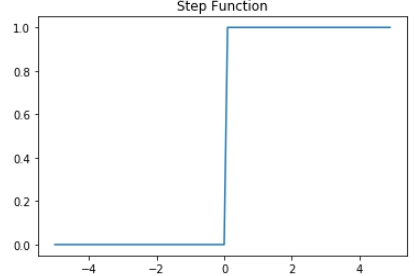 | 0 또는 1 | 단층 퍼셉트론 | 미분 불가 |
| Sigmoid 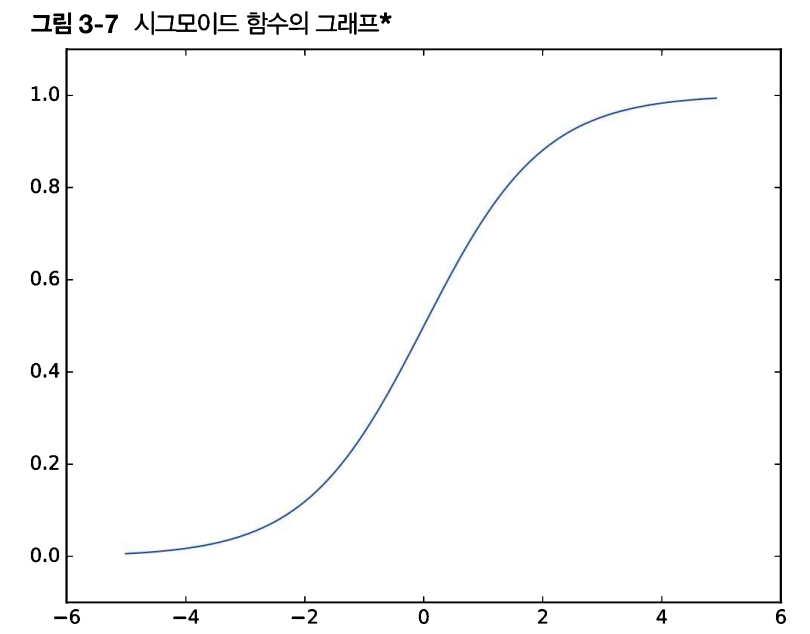 | 0 ~ 1 | 이진 분류 출력층 | 확률로 해석 가능, 기울기 소실 |
| Tanh 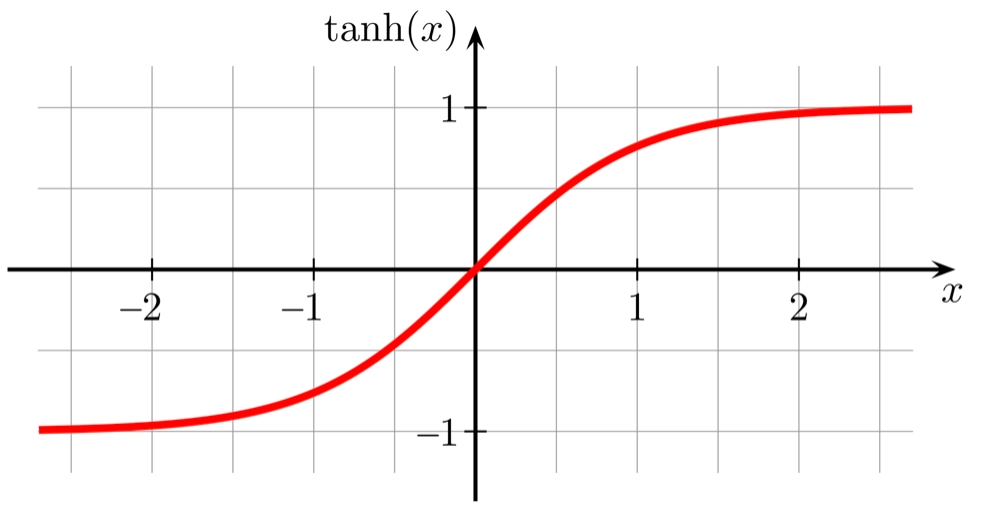| -1 ~ 1 | 은닉층 (요즘은 잘 안 씀) | 중심이 0, 기울기 소실 |
| ReLU 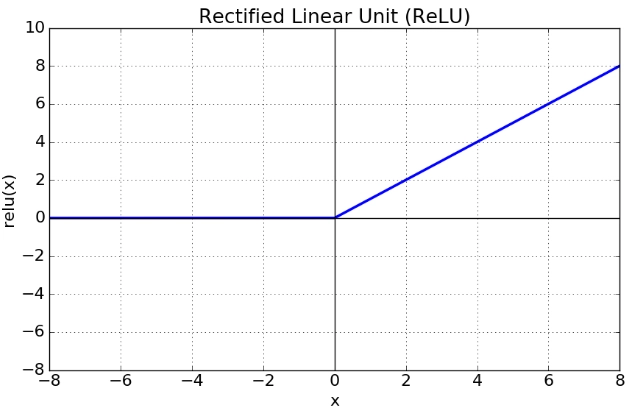| 0 ~ ∞ | 은닉층 | 계산 빠름, 음수 입력은 항상 0 |
| Softmax 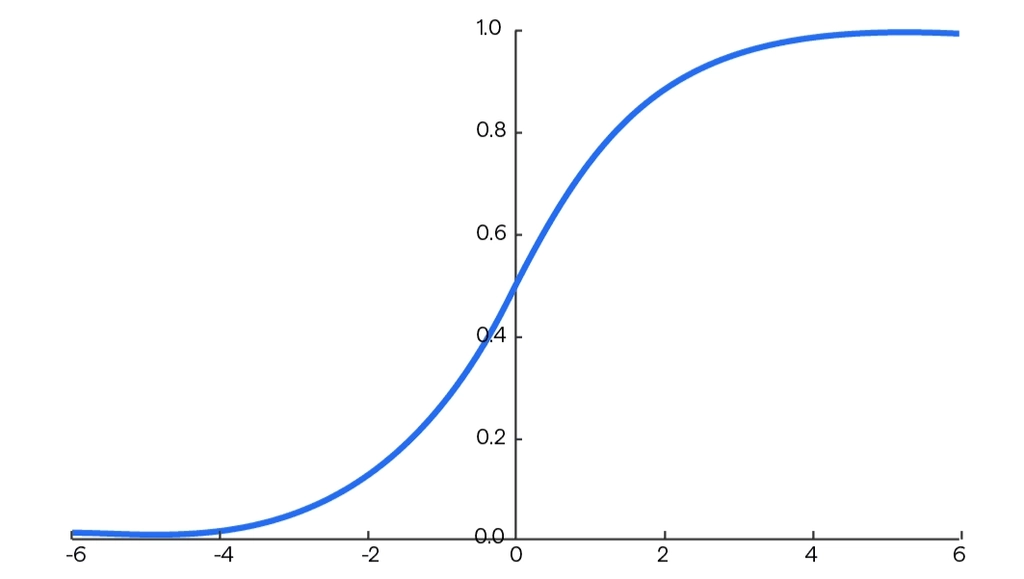| 0 ~ 1 (합 1) | 다중 분류 출력층 | 클래스별 확률 출력 |

- ReLU에서 음수 쪽 뉴런이 죽는 문제는 leaky ReLU로 보완 가능. 실무에서는 기본 ReLU를 많이 씀.
- 다중 분류는 Softmax + CEE 조합이 표준.


### <span style="color:violet"> 2-4 경사하강법 </span>
> 손실을 가장 작게 만드는 W를 찾기 위해, 기울기 반대 방향으로 조금씩 이동

$$
W \leftarrow W - \alpha \frac{\partial E}{\partial W}
$$

- 기울기가 양수면 W가 줄고, 음수면 W가 늘어서 결국 바닥(기울기 0)에 모임.
- 비유: 안개 낀 산에서 발밑 경사만 보고 한 걸음씩 내려가는 것.

> 학습률($\alpha$): 한 번에 얼마나 움직일지 정하는 하이퍼파라미터
- 너무 작으면 오래 걸리고, 너무 크면 최솟값을 지나쳐 발산함.
- 보통 0.001부터 시작 (Adam 기본값).

    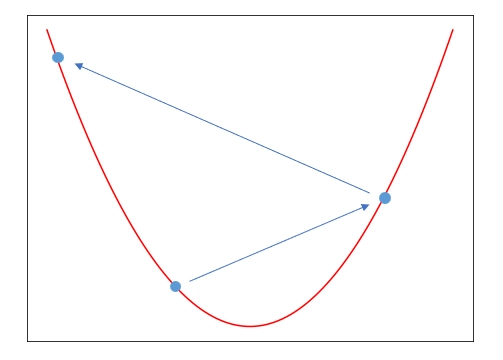


### <span style="color:violet"> 2-5 배치, 에포크, 이터레이션 </span>
> 데이터를 한 번에 다 넣으면 메모리가 부족해서 나눠서 넣음

- 배치: 한 번 업데이트에 쓰는 데이터 묶음
- 에포크: 전체 데이터를 몇 번 반복 학습하는지
- 이터레이션: 1 에포크를 끝내는 데 필요한 배치 수
    - ex. 데이터 2,000개, 배치 200 → 이터레이션 10

경사하강법은 배치 크기에 따라 세 가지로 나뉨.
- 배치 경사하강법: 전체 데이터를 한 번에 사용. 안정적이지만 메모리를 많이 씀.
- SGD: 데이터 1개씩 랜덤으로 사용. 가볍지만 불안정함.
- 미니 배치: 적당한 크기로 나눠 사용. 실무에서 가장 많이 씀 (기본값 32).


### <span style="color:violet"> 2-6 옵티마이저 </span>
> 딥러닝의 손실함수는 울퉁불퉁해서, 진짜 최솟값이 아닌 local minimum(작은 웅덩이)에 갇힐 수 있음 <Br>
이를 보완해 경사하강법을 더 잘 움직이게 하는 방법이 **옵티마이저**

- 모멘텀: 이전에 가던 방향을 기억해 관성을 줌. 작은 웅덩이를 넘어갈 수 있음.
    - 사용하는 경우: 학습이 한쪽으로 튈 때

- RMSProp: 최근 기울기를 보고 방향마다 학습률을 따로 조절함.
    - 사용하는 경우: 파라미터마다 기울기 크기 차이가 클 때

- Adam: 모멘텀 + RMSProp. 방향과 보폭을 둘 다 잡음. 일단 Adam으로 시작하면 됨.
    - 사용하는 경우: 잘 모르겠고 대부분의 경우에 씀.

